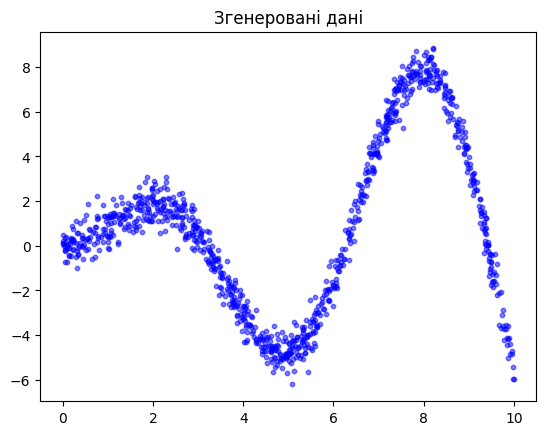

In [6]:
import random
import matplotlib.pyplot as plt
import numpy as np

n = 1000

x = np.random.uniform(0, 10, n)
y = x * np.sin(x) + np.random.normal(0, 0.5, n)

sort_indices = np.argsort(x)
x_sorted = x[sort_indices]
y_sorted = y[sort_indices]

plt.scatter(x, y, alpha=0.5, s=10, c='blue')
plt.title("Згенеровані дані")
plt.show()


y = x * sin(x) + noise

In [7]:
# 2. Функція для нормалізації
def min_max_scaler(arr):
    min_val = np.min(arr)
    max_val = np.max(arr)
    return (arr - min_val) / (max_val - min_val)

# Нормалізація відсортованих значеннь X
x_scaled = min_max_scaler(x_sorted)

x_data = x_scaled
y_data = y_sorted

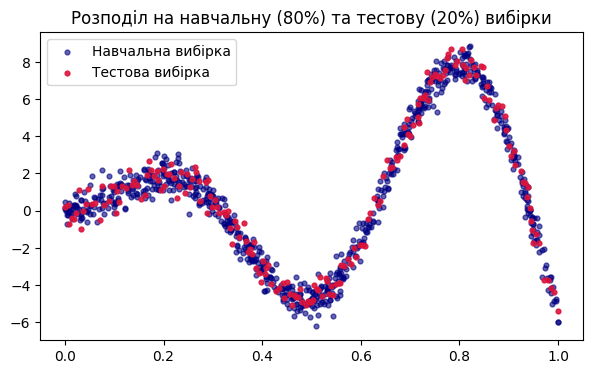

Точок для навчання: 800 | Точок для тесту: 200


In [8]:
# 3. Розділення на навчальну та тестову вибірки
x_train, y_train = [], []
x_test, y_test = [], []

for idx in range(len(x_data)):
    # 20% даних - тестова вибірка (кожен 5-й елемент, але зі зсувом)
    if idx % 5 == 3:
        x_test.append(x_data[idx])
        y_test.append(y_data[idx])
    else:
        x_train.append(x_data[idx])
        y_train.append(y_data[idx])

x_train, y_train = np.array(x_train), np.array(y_train)
x_test, y_test = np.array(x_test), np.array(y_test)

plt.figure(figsize=(7, 4))
plt.scatter(x_train, y_train, alpha=0.6, s=12, c='navy', label='Навчальна вибірка')
plt.scatter(x_test, y_test, alpha=0.9, s=12, c='crimson', label='Тестова вибірка')
plt.title("Розподіл на навчальну (80%) та тестову (20%) вибірки")
plt.legend()
plt.show()

print(f"Точок для навчання: {len(x_train)} | Точок для тесту: {len(x_test)}")

In [10]:
# 4. Навчання KNN-регресора з різними значеннями K
def custom_knn_predict(x_tr, y_tr, k, target_x):
    distances = np.abs(x_tr - target_x)              # абсолютні відстанні від цільової точки до всіх точок навчання
    nearest_indices = np.argsort(distances)[:k]      # знаходження індексів k найближчих точок

    return np.mean(y_tr[nearest_indices])

def get_predictions(x_tr, y_tr, k, x_te_array):
    predictions = []
    for val in x_te_array:
        predictions.append(custom_knn_predict(x_tr, y_tr, k, val))
    return np.array(predictions)

def calc_r2_score(y_true, y_pred):
    mean_y = np.mean(y_true)
    ss_tot = np.sum((y_true - mean_y) ** 2)         # загальна сума квадратів
    ss_res = np.sum((y_true - y_pred) ** 2)         # сума квадратів залишків
    return 1 - (ss_res / ss_tot)

In [15]:
# Функція для візуалізації результатів
def plot_regression_model(x_tr, y_tr, x_te, y_pred, k_val, r2_val):
    plt.figure(figsize=(9, 4.5))

    plt.scatter(x_tr, y_tr, color='gray', alpha=0.5, s=15, label="Тренувальні дані")                     # навчальні точки

    plt.plot(x_te, y_pred, color='darkorange', linestyle='-', linewidth=2.5, label="k-NN регресія")      # Побудована лінія k-NN на тестових точках

    plt.title(f"Модель k-NN (Кількість сусідів K={k_val}) | Точність R2 = {r2_val:.4f}")
    plt.xlabel("Нормалізована ознака X")
    plt.ylabel("Цільова змінна Y")
    plt.legend()
    plt.grid(True, linestyle=':', alpha=0.7)

    plt.show()

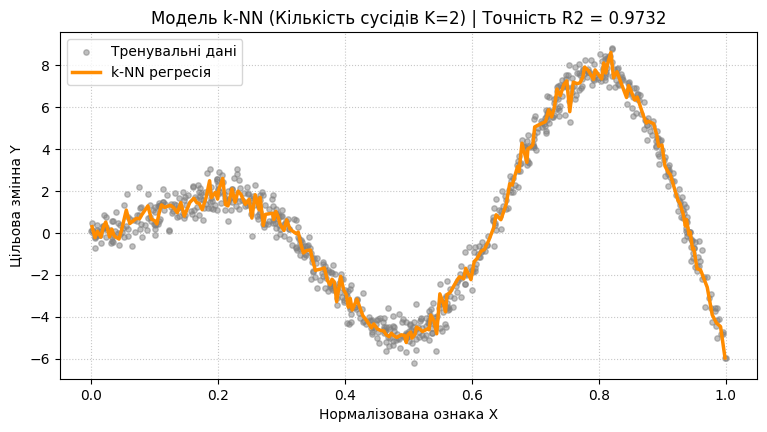

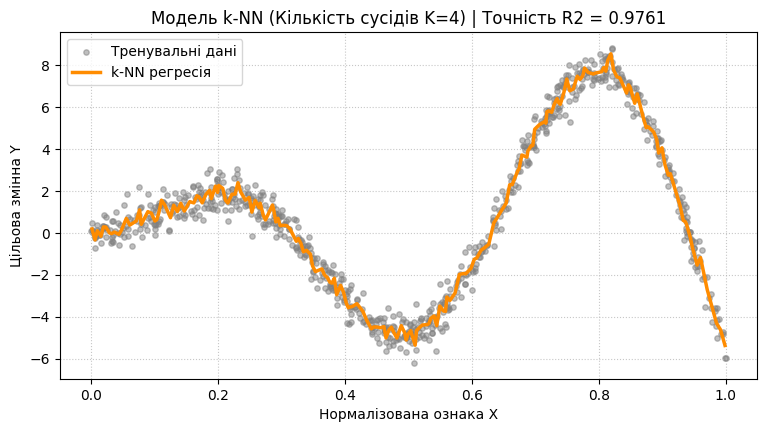

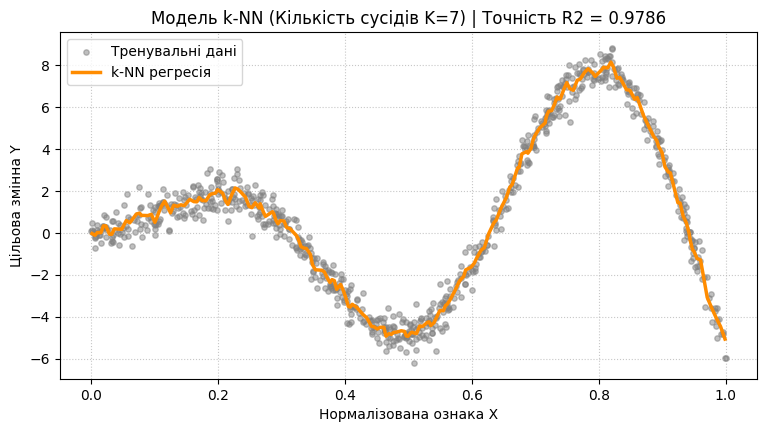

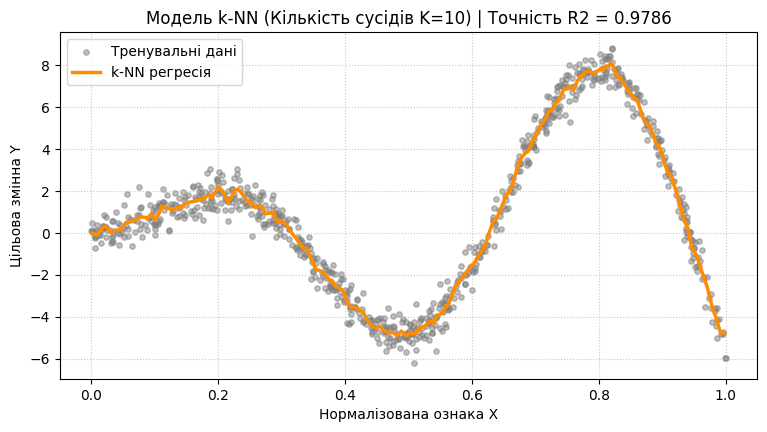

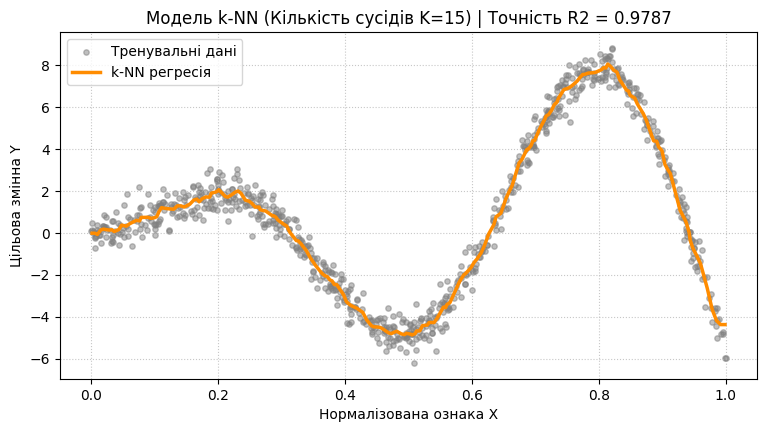

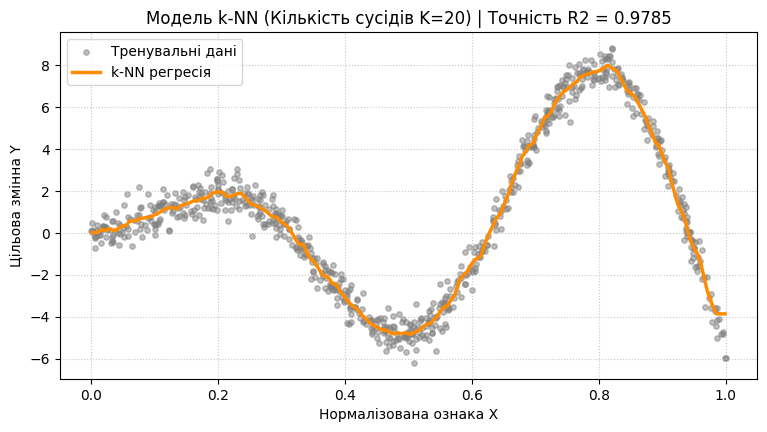

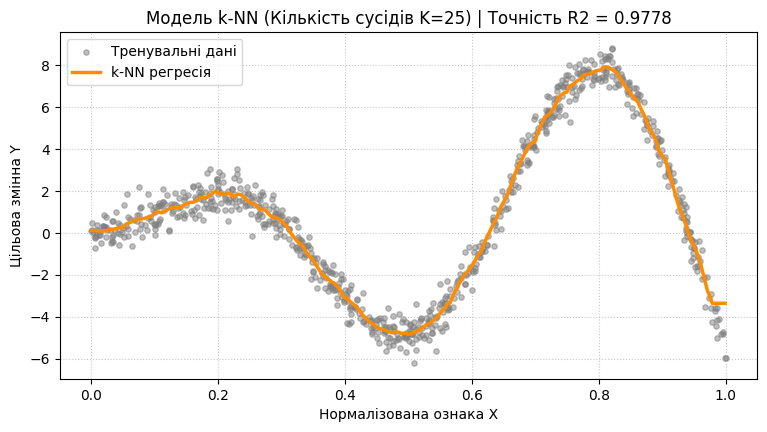

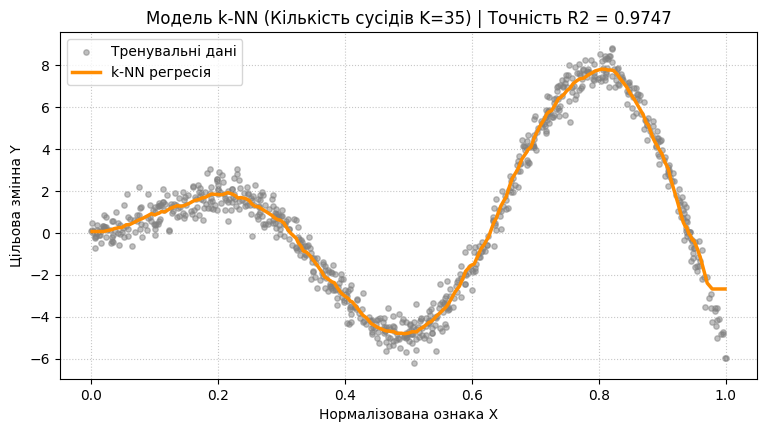

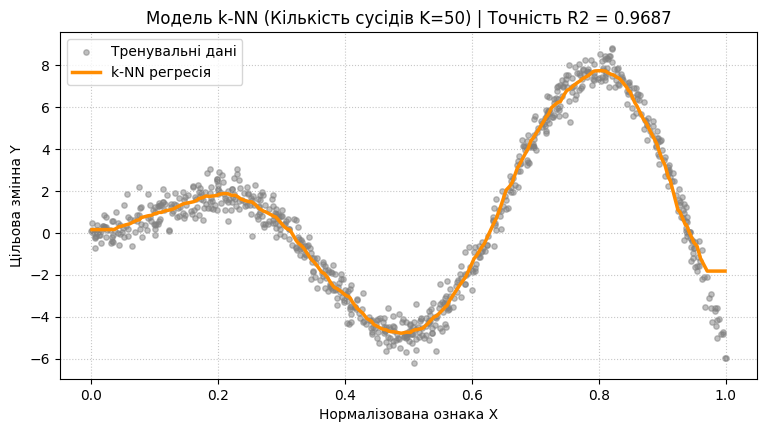

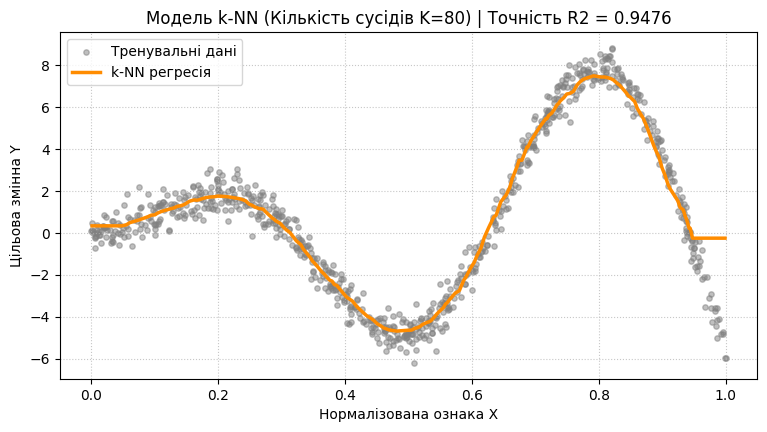

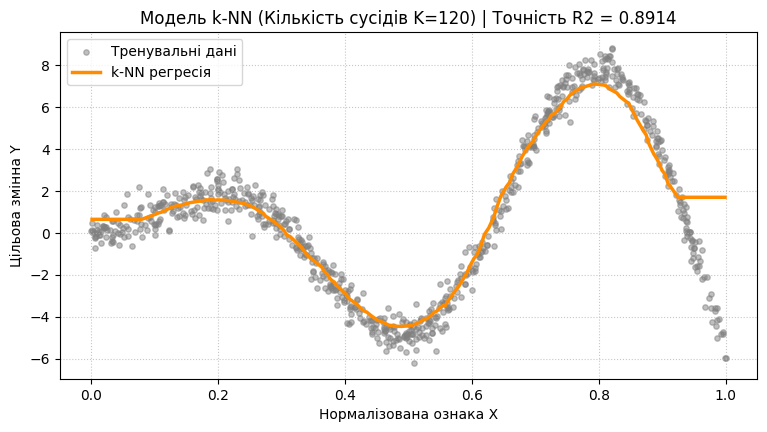

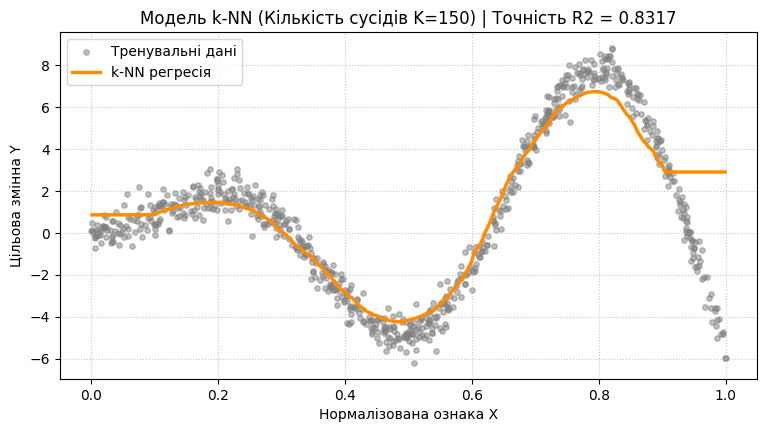

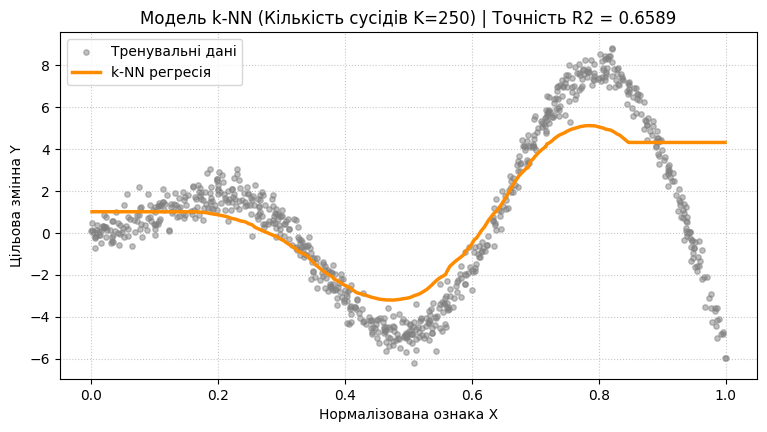

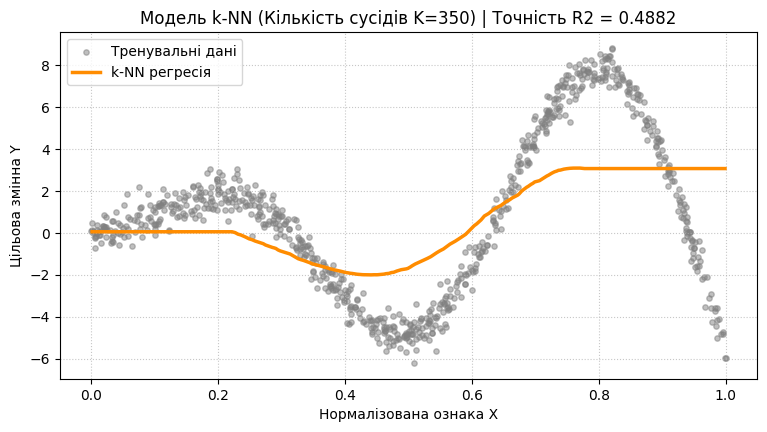

Оптимальна кількість найближчих сусідів: K = 15
Максимальний коефіцієнт детермінації (R2): 0.97873


In [16]:
# 5. Перебір значень K та вибір найкращого
neighbors_list = [2, 4, 7, 10, 15, 20, 25, 35, 50, 80, 120, 150, 250, 350]
r2_results = []

for k in neighbors_list:
    preds = get_predictions(x_train, y_train, k, x_test)     # передюачення для поточного k

    score = calc_r2_score(y_test, preds)
    r2_results.append(score)                          # розрахунок точності моделі r2

    plot_regression_model(x_train, y_train, x_test, preds, k, score)

max_r2 = max(r2_results)
best_k = neighbors_list[r2_results.index(max_r2)]

print(f"Оптимальна кількість найближчих сусідів: K = {best_k}")
print(f"Максимальний коефіцієнт детермінації (R2): {max_r2:.5f}")

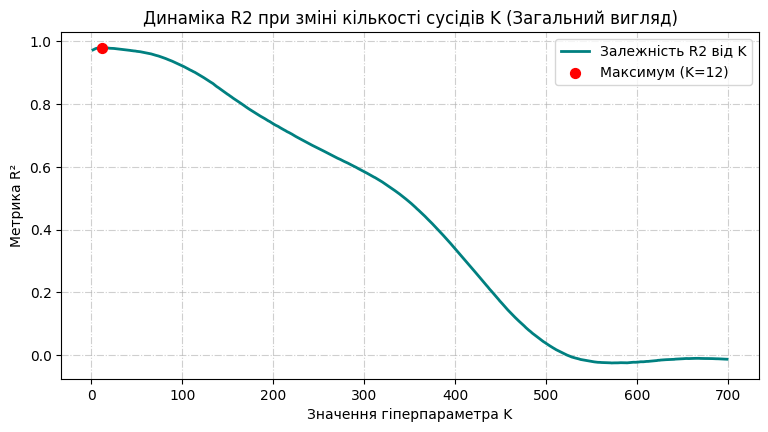

In [17]:
# 6. Розрахунок R2 для широкого діапазону K (від 2 до 700), щоб побачити загальну тенденцію
k_full_range = list(range(2, 700))
r2_full_history = []

for k in k_full_range:
    preds = get_predictions(x_train, y_train, k, x_test)
    score = calc_r2_score(y_test, preds)
    r2_full_history.append(score)


best_idx = np.argmax(r2_full_history)
best_k_global = k_full_range[best_idx]
best_r2_global = r2_full_history[best_idx]     # Пошук глобального максимуму за допомогою numpy

plt.figure(figsize=(9, 4.5))
plt.plot(k_full_range, r2_full_history, color='teal', linewidth=2, label="Залежність R2 від K")
plt.scatter([best_k_global], [best_r2_global], color='red', s=50, zorder=5, label=f"Максимум (K={best_k_global})")

plt.title("Динаміка R2 при зміні кількості сусідів K (Загальний вигляд)")
plt.xlabel("Значення гіперпараметра K")
plt.ylabel("Метрика R²")
plt.grid(True, linestyle='-.', alpha=0.6)
plt.legend()
plt.show()

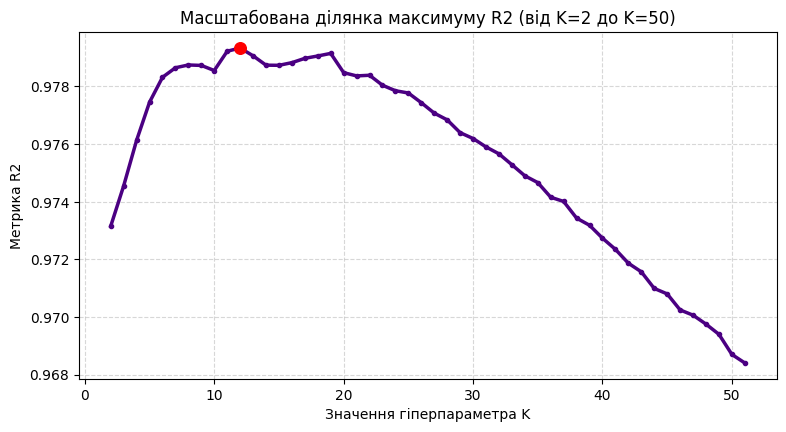

Максимальне значення R2 = 0.979337 досягається при K = 12


In [18]:
# Детальний (масштабований) вигляд початкової ділянки графіка
zoom_limit = 50
k_zoomed = k_full_range[:zoom_limit]
r2_zoomed = r2_full_history[:zoom_limit]      # Беремо перші 50 значень K, щоб чітко побачити пік


local_best_idx = np.argmax(r2_zoomed)
local_best_k = k_zoomed[local_best_idx]
local_best_r2 = r2_zoomed[local_best_idx]     # Знаходження локального максимуму на цій збільшеній ділянці

plt.figure(figsize=(9, 4.5))
plt.plot(k_zoomed, r2_zoomed, color='indigo', linewidth=2.5, marker='.') # Колір індиго
plt.scatter([local_best_k], [local_best_r2], color='red', s=70, zorder=5)

plt.title("Масштабована ділянка максимуму R2 (від K=2 до K=50)")
plt.xlabel("Значення гіперпараметра K")
plt.ylabel("Метрика R2")
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

print(f"Максимальне значення R2 = {local_best_r2:.6f} досягається при K = {local_best_k}")